In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load cleaned dataset
df = pd.read_csv("cleaned_sales_dataset.csv")

# Select numerical columns
numerical_cols = ['Age', 'Quantity', 'Unit_Price', 'Total_Sales']

numerical_data = df[numerical_cols]

# Create folder to save visualizations
os.makedirs("results/multivariate_analysis", exist_ok=True)

print("Dataset Shape:", numerical_data.shape)
display(numerical_data.head())

Dataset Shape: (1000, 4)


,Age,Quantity,Unit_Price,Total_Sales
0,30.0,7,2829.77,19808.39
1,63.0,5,27906.16,139530.80
2,62.0,8,37491.06,299928.48
3,65.0,9,28541.36,256872.24
4,44.0,10,14036.59,140365.90


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Calculate correlation matrix
correlation_matrix = numerical_data.corr(method='pearson')

# Display correlation values
print("Correlation Matrix:")
display(correlation_matrix.round(3))

# Save correlation matrix
correlation_matrix.to_csv(
    "results/multivariate_analysis/correlation_matrix.csv"
)

Correlation Matrix:


,Age,Quantity,Unit_Price,Total_Sales
Age,1.000,-0.028,-0.012,0.001
Quantity,-0.028,1.000,0.022,0.647
Unit_Price,-0.012,0.022,1.000,0.686
Total_Sales,0.001,0.647,0.686,1.000


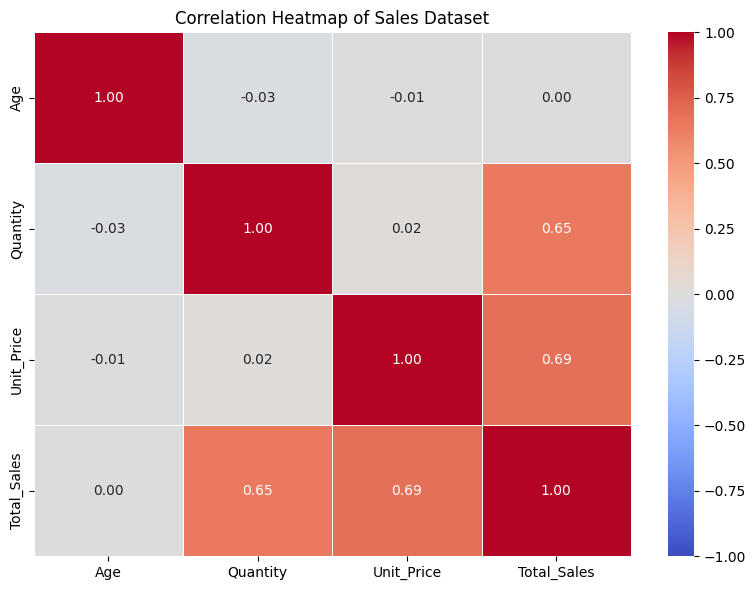

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Sales Dataset')
plt.tight_layout()

plt.savefig(
    "results/multivariate_analysis/correlation_heatmap.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

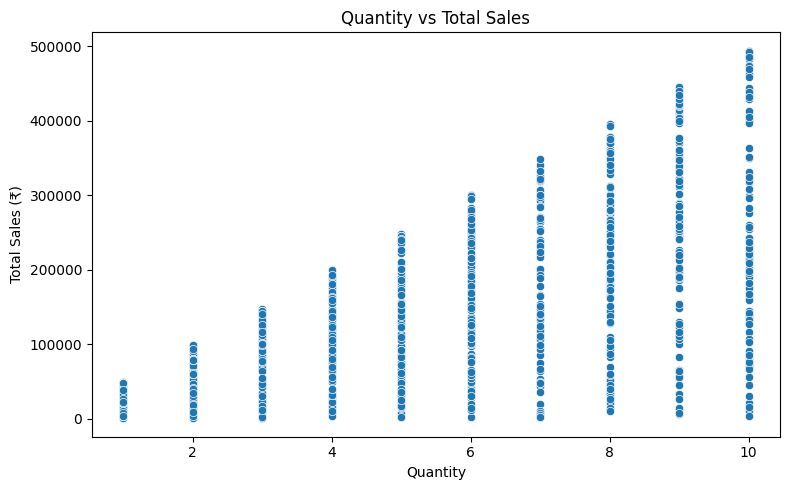

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Total_Sales'
)

plt.title('Quantity vs Total Sales')
plt.xlabel('Quantity')
plt.ylabel('Total Sales (₹)')

plt.tight_layout()
plt.savefig(
    "results/multivariate_analysis/quantity_vs_sales.png",
    dpi=300
)
plt.show()

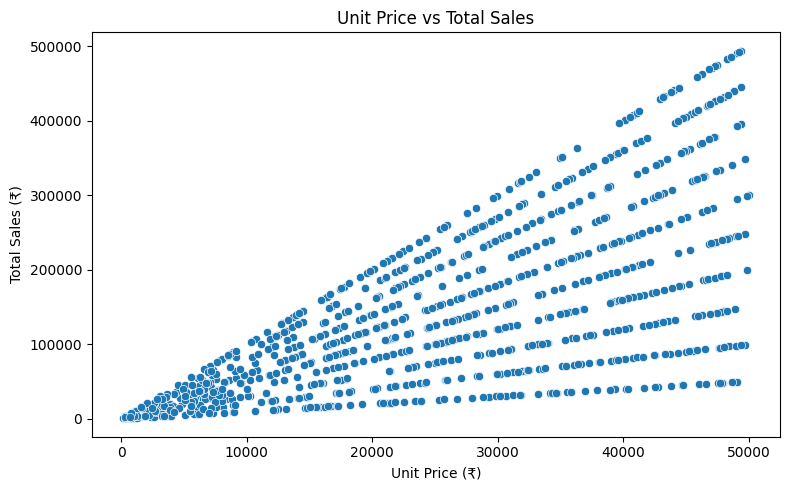

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Unit_Price',
    y='Total_Sales'
)

plt.title('Unit Price vs Total Sales')
plt.xlabel('Unit Price (₹)')
plt.ylabel('Total Sales (₹)')

plt.tight_layout()
plt.savefig(
    "results/multivariate_analysis/unit_price_vs_sales.png",
    dpi=300
)
plt.show()

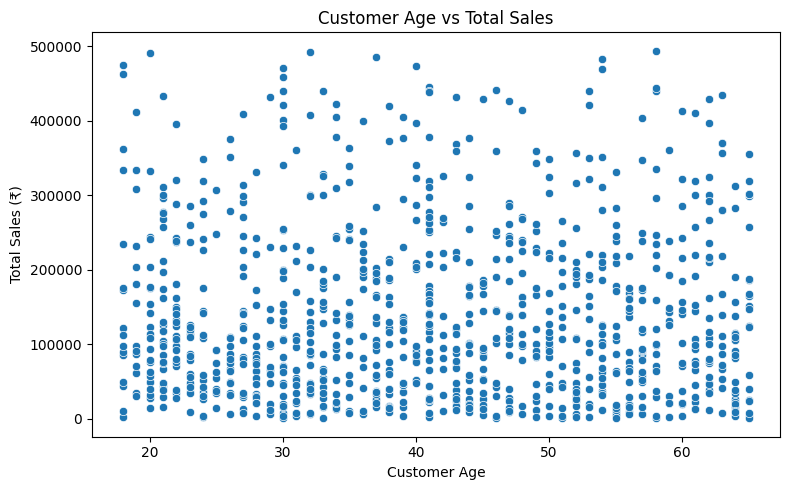

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Age',
    y='Total_Sales'
)

plt.title('Customer Age vs Total Sales')
plt.xlabel('Customer Age')
plt.ylabel('Total Sales (₹)')

plt.tight_layout()
plt.savefig(
    "results/multivariate_analysis/age_vs_sales.png",
    dpi=300
)
plt.show()

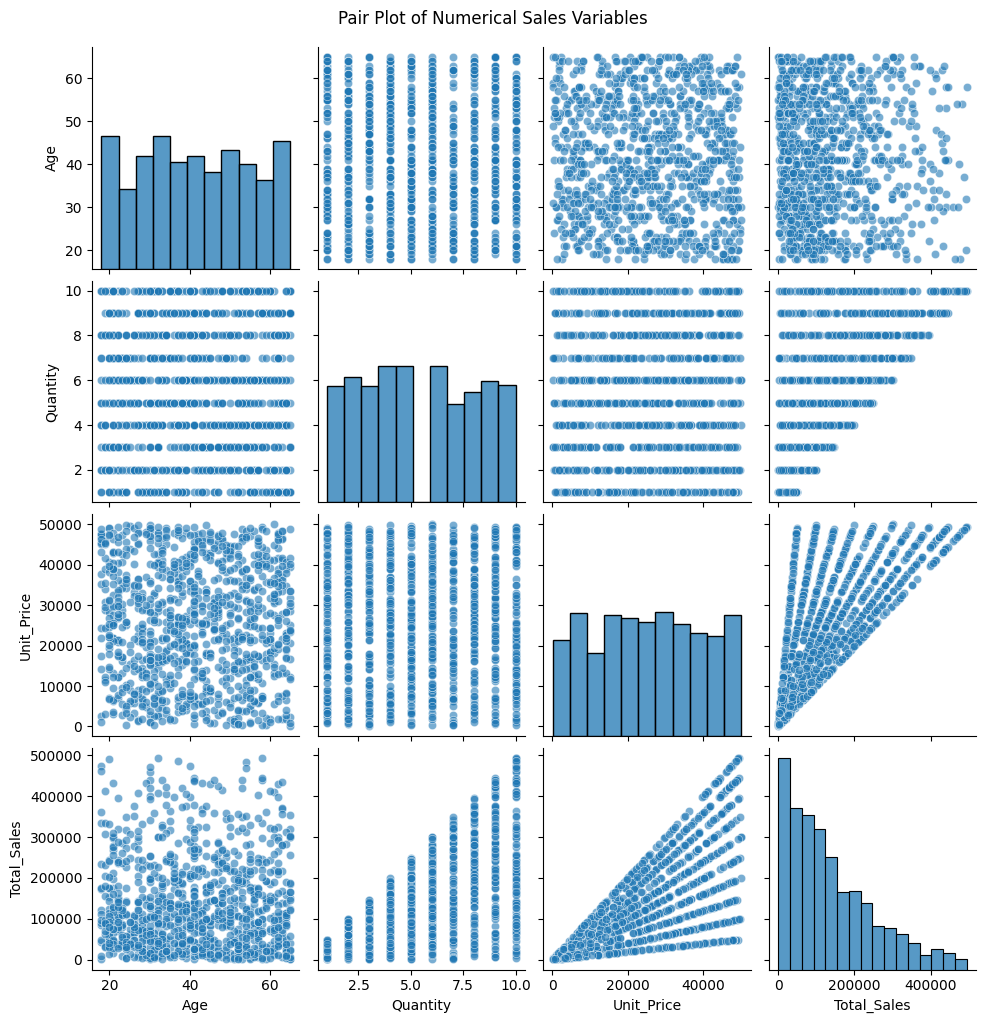

In [ ]:
pair_plot = sns.pairplot(
    numerical_data,
    diag_kind='hist',
    plot_kws={'alpha': 0.6}
)

pair_plot.fig.suptitle(
    'Pair Plot of Numerical Sales Variables',
    y=1.02
)

pair_plot.savefig(
    "results/multivariate_analysis/pair_plot.png",
    dpi=300
)

plt.show()

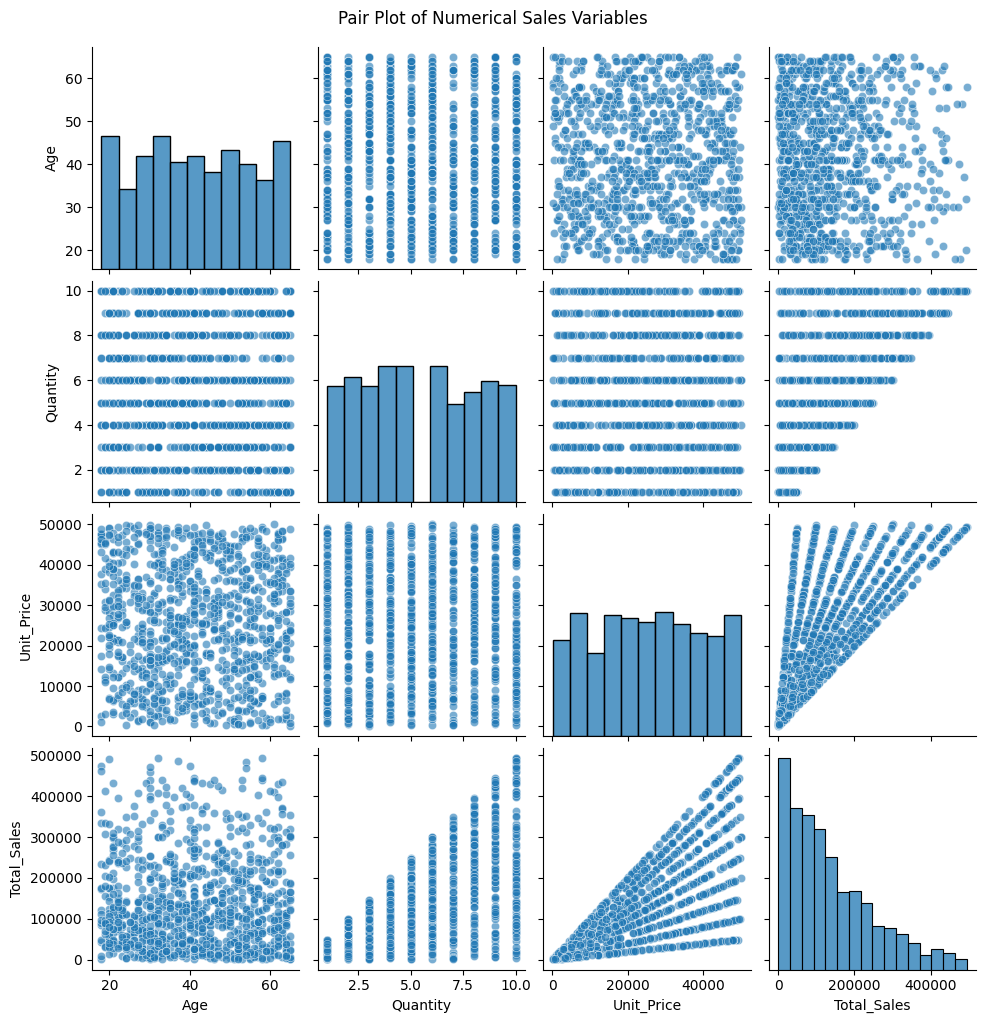

In [ ]:
pair_plot = sns.pairplot(
    numerical_data,
    diag_kind='hist',
    plot_kws={'alpha': 0.6}
)

pair_plot.fig.suptitle(
    'Pair Plot of Numerical Sales Variables',
    y=1.02
)

pair_plot.savefig(
    "results/multivariate_analysis/pair_plot.png",
    dpi=300
)

plt.show()

In [ ]:
# Extract upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Convert correlations into a list
correlation_pairs = upper_triangle.stack().reset_index()

correlation_pairs.columns = [
    'Variable_1',
    'Variable_2',
    'Correlation'
]

# Sort by absolute correlation
correlation_pairs['Absolute_Correlation'] = (
    correlation_pairs['Correlation'].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    by='Absolute_Correlation',
    ascending=False
)

print("Correlation Relationships:")
display(correlation_pairs.round(3))

# Save results
correlation_pairs.to_csv(
    "results/multivariate_analysis/correlation_relationships.csv",
    index=False
)

Correlation Relationships:


,Variable_1,Variable_2,Correlation,Absolute_Correlation
5,Unit_Price,Total_Sales,0.686,0.686
4,Quantity,Total_Sales,0.647,0.647
0,Age,Quantity,-0.028,0.028
3,Quantity,Unit_Price,0.022,0.022
1,Age,Unit_Price,-0.012,0.012
2,Age,Total_Sales,0.001,0.001
